# NLP Lab Assignment 9 — POS Tagging
## MEMM, CRF, and comparison with Naive Bayes and HMM

This notebook follows the supplied assignment PDF:
1. Train and evaluate a Maximum Entropy Markov Model (MEMM) on train/dev/test.
2. Train and evaluate a CRF POS tagger with the specified prefix, suffix, context, and binary-length features.
3. Compare MEMM, CRF, Naive Bayes, and HMM by tag and plot bar charts.

**Folder layout expected**

```text
ASS-9/
└── Lab-Assignment-9/
    ├── Hindi-POS-Data/
    │   └── ... dataset files ...
    ├── NLP-Lab-Assignment-9-2026.pdf
    └── NLP_Lab_Assignment_9.ipynb
```

Run the notebook from `Lab-Assignment-9` when possible. Since the exact files inside `Hindi-POS-Data` are not visible in the screenshot, the data-discovery cell lists the files and the loader supports common CSV, TSV, JSON/JSONL, and CoNLL-style formats. You may need to adjust the configuration cell to match the dataset used in Assignment 7.

## 1. Install dependencies

Run this cell once in the notebook's Python environment. If the environment is externally managed, use a virtual environment or a Jupyter kernel created from one.

In [8]:
%pip install -q nltk sklearn-crfsuite scikit-learn pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Imports and reproducibility

In [9]:
from pathlib import Path
import os, re, json, csv, random, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder

import nltk
from nltk.classify import MaxentClassifier
from nltk.tag import HiddenMarkovModelTrainer
from nltk.probability import LidstoneProbDist

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Find the dataset files

In [10]:
# Expected to run from Lab-Assignment-9. If not, change DATA_DIR manually.
CANDIDATE_DIRS = [
    Path("Hindi-POS-Data"),
    Path("Lab-Assignment-9/Hindi-POS-Data"),
    Path("../Lab-Assignment-9/Hindi-POS-Data"),
]

DATA_DIR = next((p.resolve() for p in CANDIDATE_DIRS if p.exists()), None)
if DATA_DIR is None:
    # Search a few levels around the notebook's working directory.
    matches = list(Path.cwd().glob("**/Hindi-POS-Data"))
    DATA_DIR = matches[0].resolve() if matches else None

print("Current working directory:", Path.cwd())
print("Dataset directory:", DATA_DIR)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find Hindi-POS-Data. Set DATA_DIR = Path('/full/path/to/Hindi-POS-Data').resolve()"
    )

files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file())
pd.DataFrame({
    "file": [str(p.relative_to(DATA_DIR)) for p in files],
    "extension": [p.suffix.lower() for p in files],
    "size_MB": [round(p.stat().st_size / (1024**2), 3) for p in files],
})

Current working directory: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-9/Lab-Assignment-9
Dataset directory: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-9/Lab-Assignment-9/Hindi-POS-Data


,file,extension,size_MB
0,hindi-dev-pos.txt,.txt,0.695
1,hindi-test-pos.txt,.txt,0.700
2,hindi-train-pos.txt,.txt,5.535


## 4. Configure and load the dataset

The loader attempts to support common POS formats:
- **CSV/TSV:** one token per row with a word/token column and a POS/tag column; optionally a sentence ID column.
- **CoNLL/TXT:** one token and tag per line, separated by tabs or whitespace; blank lines separate sentences.
- **JSON/JSONL:** lists of `{word, tag}` / `{token, pos}` objects, or sentence-level token/tag arrays.

If your Assignment 7 dataset has a different schema, update `load_pos_file()` to match it. Prefer using the original train/dev/test split when it exists.

In [11]:
# Optional explicit paths. Set these if the folder contains separate split files.
TRAIN_FILE = None   # e.g. DATA_DIR / "train.csv"
DEV_FILE   = None   # e.g. DATA_DIR / "dev.csv"
TEST_FILE  = None   # e.g. DATA_DIR / "test.csv"

WORD_KEYS = {"word", "token", "form", "text", "surface"}
TAG_KEYS  = {"tag", "pos", "upos", "xpos", "label", "category"}
SENT_KEYS = {"sentence_id", "sent_id", "sentence", "sid"}

def _normalise_key(k):
    return str(k).strip().lower().replace("-", "_").replace(" ", "_")

def _pick_col(columns, candidates):
    norm = {_normalise_key(c): c for c in columns}
    for c in candidates:
        if c in norm:
            return norm[c]
    return None

def _as_sentence_pairs(items):
    """Convert a list of token dictionaries to [(word, tag), ...]."""
    pairs = []
    for item in items:
        if not isinstance(item, dict):
            continue
        wcol = _pick_col(item.keys(), WORD_KEYS)
        tcol = _pick_col(item.keys(), TAG_KEYS)
        if wcol is not None and tcol is not None:
            w, t = item[wcol], item[tcol]
            if pd.notna(w) and pd.notna(t):
                pairs.append((str(w), str(t)))
    return pairs

def load_pos_file(path):
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in {".csv", ".tsv"}:
        sep = "\t" if suffix == ".tsv" else None
        df = pd.read_csv(path, sep=sep, engine="python", encoding="utf-8", on_bad_lines="skip")
        wcol = _pick_col(df.columns, WORD_KEYS)
        tcol = _pick_col(df.columns, TAG_KEYS)
        scol = _pick_col(df.columns, SENT_KEYS)
        if wcol is None or tcol is None:
            raise ValueError(f"{path.name}: could not identify word/tag columns. Columns: {list(df.columns)}")
        df = df[[wcol, tcol] + ([scol] if scol else [])].dropna(subset=[wcol, tcol])
        if scol:
            out = []
            for _, group in df.groupby(scol, sort=False):
                sent = [(str(w), str(t)) for w, t in zip(group[wcol], group[tcol])]
                if sent: out.append(sent)
            return out
        # Without sentence IDs, treat each row as a separate one-token sentence.
        # This is valid for token-level baselines, but context models benefit from sentence boundaries.
        return [[(str(w), str(t))] for w, t in zip(df[wcol], df[tcol])]

    if suffix in {".json", ".jsonl"}:
        raw_text = path.read_text(encoding="utf-8")
        try:
            obj = json.loads(raw_text)
        except json.JSONDecodeError:
            obj = [json.loads(line) for line in raw_text.splitlines() if line.strip()]
        if isinstance(obj, dict):
            for key in ("sentences", "data", "records", "examples"):
                if key in obj:
                    obj = obj[key]
                    break
        if isinstance(obj, list):
            # Sentence list: each item is a list of token dictionaries.
            if obj and isinstance(obj[0], list):
                result = []
                for sent in obj:
                    pairs = _as_sentence_pairs(sent)
                    if pairs: result.append(pairs)
                if result: return result
            # Row-level records with sentence identifier.
            if obj and isinstance(obj[0], dict):
                wcol = _pick_col(obj[0].keys(), WORD_KEYS)
                tcol = _pick_col(obj[0].keys(), TAG_KEYS)
                scol = _pick_col(obj[0].keys(), SENT_KEYS)
                if wcol is not None and tcol is not None:
                    df = pd.DataFrame(obj).dropna(subset=[wcol, tcol])
                    if scol:
                        return [[(str(w), str(t)) for w, t in zip(g[wcol], g[tcol])]
                                for _, g in df.groupby(scol, sort=False)]
                    pairs = _as_sentence_pairs(obj)
                    return [[p] for p in pairs]
        raise ValueError(f"Unsupported JSON structure in {path.name}")

    if suffix in {".txt", ".conll", ".conllu", ".tsv"}:
        sentences, current = [], []
        for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
            line = line.strip()
            if not line:
                if current:
                    sentences.append(current); current = []
                continue
            if line.startswith("#"):
                continue
            parts = line.split("\t") if "\t" in line else line.split()
            if len(parts) < 2:
                continue
            # Standard CoNLL-U: ID FORM LEMMA UPOS XPOS ...; otherwise assume WORD TAG.
            if len(parts) >= 4 and parts[0].isdigit():
                word, tag = parts[1], parts[3]
            else:
                word, tag = parts[0], parts[-1]
            if word != "_" and tag != "_":
                current.append((word, tag))
        if current: sentences.append(current)
        if not sentences:
            raise ValueError(f"No word/tag rows parsed from {path.name}")
        return sentences

    raise ValueError(f"Unsupported file extension: {suffix}")

def load_split(path):
    sents = load_pos_file(path)
    return [s for s in sents if s]

def choose_file(split_name, explicit):
    if explicit is not None:
        p = Path(explicit)
        if not p.exists(): raise FileNotFoundError(p)
        return p
    patterns = {
        "train": ["*train*.csv", "*train*.tsv", "*train*.conll", "*train*.txt", "*train*.json*"],
        "dev":   ["*dev*.csv", "*valid*.csv", "*dev*.tsv", "*valid*.tsv", "*dev*.conll", "*valid*.conll", "*dev*.txt", "*valid*.txt"],
        "test":  ["*test*.csv", "*test*.tsv", "*test*.conll", "*test*.txt", "*test*.json*"],
    }
    found = []
    for pattern in patterns[split_name]:
        found.extend(DATA_DIR.rglob(pattern))
    found = sorted(set(p for p in found if p.is_file()))
    return found[0] if found else None

train_path = choose_file("train", TRAIN_FILE)
dev_path = choose_file("dev", DEV_FILE)
test_path = choose_file("test", TEST_FILE)

print("Detected train:", train_path)
print("Detected dev:  ", dev_path)
print("Detected test: ", test_path)

Detected train: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-9/Lab-Assignment-9/Hindi-POS-Data/hindi-train-pos.txt
Detected dev:   /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-9/Lab-Assignment-9/Hindi-POS-Data/hindi-dev-pos.txt
Detected test:  /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-9/Lab-Assignment-9/Hindi-POS-Data/hindi-test-pos.txt


### If no train/dev/test files were detected

If the dataset has one file only, use the next cell to load it and create a reproducible 80/10/10 sentence-level split. This is a fallback, not a replacement for an official split if your Assignment 7 data already provides one.

In [12]:
if train_path and dev_path and test_path:
    train_sents = load_split(train_path)
    dev_sents = load_split(dev_path)
    test_sents = load_split(test_path)
    SPLIT_NOTE = "Using detected or explicitly configured train/dev/test files."
else:
    # Find supported data files; avoid PDFs and hidden files.
    supported = {".csv", ".tsv", ".txt", ".conll", ".conllu", ".json", ".jsonl"}
    candidates = [p for p in files if p.suffix.lower() in supported]
    if not candidates:
        raise FileNotFoundError("No supported dataset files found. Inspect the file list and configure the loader.")
    # Prefer a single likely main corpus file over a split file.
    non_split = [p for p in candidates if not re.search(r"(train|dev|valid|test)", p.stem, re.I)]
    source = non_split[0] if non_split else candidates[0]
    all_sents = load_split(source)
    if len(all_sents) < 10:
        warnings.warn("Very few sentence records were loaded. Verify the dataset format and sentence boundaries.")
    train_sents, remainder = train_test_split(all_sents, test_size=0.2, random_state=RANDOM_STATE)
    dev_sents, test_sents = train_test_split(remainder, test_size=0.5, random_state=RANDOM_STATE)
    SPLIT_NOTE = f"Fallback 80/10/10 sentence split from {source.name}; confirm this matches Assignment 7."
    print("Fallback source:", source)

print(SPLIT_NOTE)
print(f"Train sentences: {len(train_sents):,} | Dev sentences: {len(dev_sents):,} | Test sentences: {len(test_sents):,}")

def validate_sents(sents, name):
    n_tokens = sum(len(s) for s in sents)
    tags = Counter(tag for sent in sents for _, tag in sent)
    print(f"{name}: {len(sents):,} sentences, {n_tokens:,} tokens, {len(tags)} unique tags")
    print("Most common tags:", tags.most_common(15))
    return tags

train_tags = validate_sents(train_sents, "Train")
validate_sents(dev_sents, "Dev")
validate_sents(test_sents, "Test")
print("Example:", train_sents[0][:15] if train_sents else "No sentences loaded")

Using detected or explicitly configured train/dev/test files.
Train sentences: 15,087 | Dev sentences: 1,866 | Test sentences: 1,910
Train: 15,087 sentences, 325,710 tokens, 24 unique tags
Most common tags: [('N_NN', 71442), ('PSP', 64342), ('N_NNP', 39578), ('V_VM', 34495), ('V_VAUX', 20695), ('RD_PUNC', 19683), ('JJ', 18281), ('PR_PRP', 11543), ('QT_QTC', 6456), ('CC_CCD', 6319), ('CC_CCS', 6058), ('N_NST', 4995), ('RP_RPD', 4961), ('DM_DMD', 4380), ('RD_SYM', 2858)]
Dev: 1,866 sentences, 40,762 tokens, 24 unique tags
Most common tags: [('N_NN', 9098), ('PSP', 8023), ('N_NNP', 4853), ('V_VM', 4253), ('V_VAUX', 2544), ('RD_PUNC', 2487), ('JJ', 2370), ('PR_PRP', 1428), ('QT_QTC', 856), ('CC_CCD', 829), ('CC_CCS', 752), ('RP_RPD', 647), ('N_NST', 621), ('DM_DMD', 499), ('RD_SYM', 361)]
Test: 1,910 sentences, 41,415 tokens, 24 unique tags
Most common tags: [('N_NN', 9303), ('PSP', 8245), ('N_NNP', 5296), ('V_VM', 4174), ('RD_PUNC', 2549), ('V_VAUX', 2534), ('JJ', 2258), ('PR_PRP', 1338),

## 5. Evaluation helper

Metrics are computed at token level. The classification report includes per-tag precision, recall, F1, and support. The same test gold labels are used for all models.

In [13]:
def flatten_gold(sents):
    return [tag for sent in sents for _, tag in sent]

def evaluate_predictions(name, gold_sents, pred_sents, labels=None):
    y_true = flatten_gold(gold_sents)
    y_pred = [tag for sent in pred_sents for tag in sent]
    if len(y_true) != len(y_pred):
        raise ValueError(f"{name}: prediction length {len(y_pred)} != gold length {len(y_true)}")
    if labels is None:
        labels = sorted(set(y_true) | set(y_pred))
    print(f"===== {name} =====")
    print("Token accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, labels=labels, zero_division=0, digits=4))
    report = classification_report(y_true, y_pred, labels=labels, zero_division=0, output_dict=True)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "report": report,
        "y_true": y_true,
        "y_pred": y_pred,
    }

## 6. MEMM (Maximum Entropy Markov Model)

A MEMM predicts the current tag using the current word/context and the previous predicted tag. NLTK's `MaxentClassifier` provides the maximum-entropy classifier; greedy decoding supplies the Markov dependency on the previous tag. This is a practical MEMM implementation using the same train/dev/test data.

In [14]:
def memm_features(sentence, i, prev_tag):
    word = sentence[i][0]
    lower = word.lower()
    return {
        "bias": True,
        "word": lower,
        "word.isupper": word.isupper(),
        "word.istitle": word.istitle(),
        "word.isdigit": word.isdigit(),
        "prefix1": lower[:1] if len(lower) >= 1 else "NULL",
        "prefix2": lower[:2] if len(lower) >= 2 else "NULL",
        "prefix3": lower[:3] if len(lower) >= 3 else "NULL",
        "prefix4": lower[:4] if len(lower) >= 4 else "NULL",
        "suffix1": lower[-1:] if len(lower) >= 1 else "NULL",
        "suffix2": lower[-2:] if len(lower) >= 2 else "NULL",
        "suffix3": lower[-3:] if len(lower) >= 3 else "NULL",
        "suffix4": lower[-4:] if len(lower) >= 4 else "NULL",
        "prev_word": sentence[i-1][0].lower() if i > 0 else "<BOS>",
        "next_word": sentence[i+1][0].lower() if i+1 < len(sentence) else "<EOS>",
        "prev_tag": prev_tag,
        "length_feature": "LESS" if len(word) <= 4 else "MORE",
    }

def memm_training_examples(sents):
    examples = []
    for sent in sents:
        prev_tag = "<START>"
        for i, (word, tag) in enumerate(sent):
            examples.append((memm_features(sent, i, prev_tag), tag))
            prev_tag = tag
    return examples

# Training can take time for a large corpus. Lower max_iter for a quick trial if needed.
memm_train = memm_training_examples(train_sents)
print("MEMM training examples:", len(memm_train))
memm_classifier = MaxentClassifier.train(
    memm_train,
    algorithm="iis",
    max_iter=10,
    trace=1,
)

MEMM training examples: 325710
  ==> Training (10 iterations)


In [15]:
def predict_memm_sentence(sentence, classifier):
    pred, prev_tag = [], "<START>"
    for i, _ in enumerate(sentence):
        tag = classifier.classify(memm_features(sentence, i, prev_tag))
        pred.append(tag)
        prev_tag = tag
    return pred

memm_dev_pred = [predict_memm_sentence(s, memm_classifier) for s in dev_sents]
memm_test_pred = [predict_memm_sentence(s, memm_classifier) for s in test_sents]

memm_dev_result = evaluate_predictions("MEMM — Dev", dev_sents, memm_dev_pred)
memm_test_result = evaluate_predictions("MEMM — Test", test_sents, memm_test_pred)

===== MEMM — Dev =====
Token accuracy: 0.9378
              precision    recall  f1-score   support

      CC_CCD     0.9730    0.9144    0.9428       829
      CC_CCS     0.9699    0.9867    0.9782       752
      DM_DMD     0.8698    0.8838    0.8767       499
          JJ     0.9207    0.8911    0.9057      2370
        N_NN     0.8984    0.9586    0.9275      9098
       N_NNP     0.9146    0.8253    0.8676      4853
       N_NST     0.9902    0.9775    0.9838       621
      PR_PRF     0.9934    0.9934    0.9934       152
      PR_PRL     0.9691    0.8868    0.9261       106
      PR_PRP     0.9710    0.9153    0.9423      1428
      PR_PRQ     1.0000    0.9600    0.9796        25
         PSP     0.9501    0.9914    0.9703      8023
      QT_QTC     0.9386    0.9463    0.9424       856
      QT_QTF     0.9314    0.8636    0.8962       330
      QT_QTO     0.9643    0.8182    0.8852        66
          RB     0.8447    0.8447    0.8447       161
     RD_PUNC     0.9884    0.9626  

## 7. CRF POS tagger

The CRF uses the exact feature groups requested in the assignment:
- Prefixes of length 1–4; unavailable prefixes are `NULL`.
- Suffixes of length 1–4; unavailable suffixes are `NULL`.
- Previous, current, and next word.
- Binary length feature: `LESS` if word length is ≤ 4, otherwise `MORE`.

`sklearn-crfsuite` is used as requested in the assignment.

In [16]:
def crf_token_features(sentence, i):
    word = sentence[i][0]
    lower = word.lower()
    prev_word = sentence[i-1][0].lower() if i > 0 else "<BOS>"
    next_word = sentence[i+1][0].lower() if i+1 < len(sentence) else "<EOS>"
    return {
        "prefix1": lower[:1] if len(lower) >= 1 else "NULL",
        "prefix2": lower[:2] if len(lower) >= 2 else "NULL",
        "prefix3": lower[:3] if len(lower) >= 3 else "NULL",
        "prefix4": lower[:4] if len(lower) >= 4 else "NULL",
        "suffix1": lower[-1:] if len(lower) >= 1 else "NULL",
        "suffix2": lower[-2:] if len(lower) >= 2 else "NULL",
        "suffix3": lower[-3:] if len(lower) >= 3 else "NULL",
        "suffix4": lower[-4:] if len(lower) >= 4 else "NULL",
        "previous_word": prev_word,
        "current_word": lower,
        "next_word": next_word,
        "length_feature": "LESS" if len(word) <= 4 else "MORE",
    }

def sent_to_crf_features(sent):
    return [crf_token_features(sent, i) for i in range(len(sent))]

X_train_crf = [sent_to_crf_features(s) for s in train_sents]
y_train_crf = [[tag for _, tag in s] for s in train_sents]
X_dev_crf = [sent_to_crf_features(s) for s in dev_sents]
y_dev_crf = [[tag for _, tag in s] for s in dev_sents]
X_test_crf = [sent_to_crf_features(s) for s in test_sents]
y_test_crf = [[tag for _, tag in s] for s in test_sents]

try:
    import sklearn_crfsuite
except ImportError as e:
    raise ImportError("Install sklearn-crfsuite with %pip install sklearn-crfsuite, then rerun this cell.") from e

crf = sklearn_crfsuite.CRF(
    algorithm="lbfgs",
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True,
)
crf.fit(X_train_crf, y_train_crf)

,algorithm,'lbfgs'
,all_possible_transitions,True
,c1,0.1
,c2,0.1
,max_iterations,100
,min_freq,None
,all_possible_states,None
,num_memories,None
,epsilon,None
,period,None
,delta,None


In [17]:
crf_dev_pred = crf.predict(X_dev_crf)
crf_test_pred = crf.predict(X_test_crf)
crf_dev_result = evaluate_predictions("CRF — Dev", dev_sents, crf_dev_pred)
crf_test_result = evaluate_predictions("CRF — Test", test_sents, crf_test_pred)

===== CRF — Dev =====
Token accuracy: 0.9634
              precision    recall  f1-score   support

      CC_CCD     0.9844    0.9916    0.9880       829
      CC_CCS     0.9777    0.9920    0.9848       752
      DM_DMD     0.9587    0.9780    0.9683       499
          JJ     0.9346    0.9169    0.9257      2370
        N_NN     0.9293    0.9536    0.9413      9098
       N_NNP     0.9106    0.8772    0.8936      4853
       N_NST     0.9920    0.9952    0.9936       621
      PR_PRF     1.0000    1.0000    1.0000       152
      PR_PRL     0.9619    0.9528    0.9573       106
      PR_PRP     0.9844    0.9734    0.9789      1428
      PR_PRQ     0.9615    1.0000    0.9804        25
         PSP     0.9971    0.9981    0.9976      8023
      QT_QTC     0.9698    0.9755    0.9726       856
      QT_QTF     0.9776    0.9242    0.9502       330
      QT_QTO     0.9836    0.9091    0.9449        66
          RB     0.8562    0.8509    0.8536       161
     RD_PUNC     1.0000    1.0000   

## 8. Naive Bayes baseline

This token-level Naive Bayes baseline predicts tags from lexical and simple shape features without sequence decoding. It is included for the comparative study. For a strict comparison, use the same train/dev/test split as the sequence models.

In [18]:
def nb_features(word):
    w = str(word)
    lower = w.lower()
    return {
        "word": lower,
        "prefix1": lower[:1] if len(lower) >= 1 else "NULL",
        "prefix2": lower[:2] if len(lower) >= 2 else "NULL",
        "suffix1": lower[-1:] if len(lower) >= 1 else "NULL",
        "suffix2": lower[-2:] if len(lower) >= 2 else "NULL",
        "is_upper": str(w.isupper()),
        "is_title": str(w.istitle()),
        "is_digit": str(w.isdigit()),
        "length_feature": "LESS" if len(w) <= 4 else "MORE",
    }

nb_train = [(nb_features(w), t) for s in train_sents for w, t in s]
nb_classifier = nltk.NaiveBayesClassifier.train(nb_train)

def predict_nb_sents(sents):
    return [[nb_classifier.classify(nb_features(w)) for w, _ in s] for s in sents]

nb_dev_pred = predict_nb_sents(dev_sents)
nb_test_pred = predict_nb_sents(test_sents)
nb_dev_result = evaluate_predictions("Naive Bayes — Dev", dev_sents, nb_dev_pred)
nb_test_result = evaluate_predictions("Naive Bayes — Test", test_sents, nb_test_pred)

===== Naive Bayes — Dev =====
Token accuracy: 0.8835
              precision    recall  f1-score   support

      CC_CCD     0.9598    0.9783    0.9689       829
      CC_CCS     0.9291    0.9934    0.9602       752
      DM_DMD     0.8010    0.9279    0.8598       499
          JJ     0.7543    0.8979    0.8199      2370
        N_NN     0.8806    0.8773    0.8790      9098
       N_NNP     0.8240    0.7035    0.7590      4853
       N_NST     0.8659    0.9775    0.9183       621
      PR_PRF     0.9742    0.9934    0.9837       152
      PR_PRL     0.7939    0.9811    0.8776       106
      PR_PRP     0.9447    0.8859    0.9143      1428
      PR_PRQ     0.6486    0.9600    0.7742        25
         PSP     0.9696    0.9743    0.9720      8023
      QT_QTC     0.7800    0.9731    0.8659       856
      QT_QTF     0.8542    0.8697    0.8619       330
      QT_QTO     0.6000    0.9091    0.7229        66
          RB     0.4859    0.7516    0.5902       161
     RD_PUNC     1.0000    1

## 9. HMM baseline

This HMM baseline is trained using NLTK's `HiddenMarkovModelTrainer` on the same tagged sentences. It models transitions between tags and emissions from tags to words.

In [19]:
hmm_trainer = HiddenMarkovModelTrainer()
hmm_tagger = hmm_trainer.train_supervised(
    train_sents,
    estimator=lambda fd, bins: LidstoneProbDist(fd, 0.1, bins)
)

def predict_hmm_sents(sents):
    outputs = []
    for sent in sents:
        words = [w for w, _ in sent]
        tagged = hmm_tagger.tag(words)
        outputs.append([tag for _, tag in tagged])
    return outputs

hmm_dev_pred = predict_hmm_sents(dev_sents)
hmm_test_pred = predict_hmm_sents(test_sents)
hmm_dev_result = evaluate_predictions("HMM — Dev", dev_sents, hmm_dev_pred)
hmm_test_result = evaluate_predictions("HMM — Test", test_sents, hmm_test_pred)

===== HMM — Dev =====
Token accuracy: 0.9304
              precision    recall  f1-score   support

      CC_CCD     0.9413    0.9867    0.9635       829
      CC_CCS     0.9258    0.9960    0.9596       752
      DM_DMD     0.8354    0.9659    0.8959       499
          JJ     0.8858    0.8869    0.8864      2370
        N_NN     0.9303    0.8995    0.9147      9098
       N_NNP     0.8735    0.8055    0.8381      4853
       N_NST     0.9079    0.9839    0.9444       621
      PR_PRF     0.9870    1.0000    0.9935       152
      PR_PRL     0.8235    0.9245    0.8711       106
      PR_PRP     0.9383    0.9692    0.9535      1428
      PR_PRQ     0.9583    0.9200    0.9388        25
         PSP     0.9808    0.9869    0.9838      8023
      QT_QTC     0.8086    0.9182    0.8600       856
      QT_QTF     0.9212    0.9212    0.9212       330
      QT_QTO     0.8750    0.7424    0.8033        66
          RB     0.8355    0.7888    0.8115       161
     RD_PUNC     0.9885    1.0000   

## 10. Overall comparison

The table compares token accuracy, macro F1, and weighted F1 on the same dev and test sets. Macro F1 gives each tag equal weight; weighted F1 accounts for tag frequency.

In [20]:
all_results = [
    memm_dev_result, crf_dev_result, nb_dev_result, hmm_dev_result,
    memm_test_result, crf_test_result, nb_test_result, hmm_test_result,
]
overall_df = pd.DataFrame([
    {k: r[k] for k in ("model", "accuracy", "macro_f1", "weighted_f1")}
    for r in all_results
])
overall_df.sort_values(["model"], inplace=True)
display(overall_df.style.format({
    "accuracy": "{:.4f}", "macro_f1": "{:.4f}", "weighted_f1": "{:.4f}"
}))

,model,accuracy,macro_f1,weighted_f1
1,CRF — Dev,0.9634,0.9649,0.9633
5,CRF — Test,0.9645,0.9288,0.9644
3,HMM — Dev,0.9304,0.9083,0.9301
7,HMM — Test,0.9283,0.8685,0.9281
0,MEMM — Dev,0.9378,0.9288,0.9374
4,MEMM — Test,0.9382,0.8861,0.9378
2,Naive Bayes — Dev,0.8835,0.8268,0.8831
6,Naive Bayes — Test,0.8812,0.8113,0.8815


## 11. Per-tag comparative study and bar charts

The assignment asks for performance by each tag and bar charts. We plot **per-tag F1-score** on the test set for MEMM, CRF, Naive Bayes, and HMM. Tags absent from a model's predictions are retained with an F1 of zero via `zero_division=0`.

In [21]:
test_results = {
    "MEMM": memm_test_result,
    "CRF": crf_test_result,
    "Naive Bayes": nb_test_result,
    "HMM": hmm_test_result,
}

all_tags = sorted(set(flatten_gold(test_sents)))
per_tag_rows = []
for tag in all_tags:
    row = {"tag": tag}
    for model_name, result in test_results.items():
        row[model_name] = result["report"].get(tag, {}).get("f1-score", 0.0)
    per_tag_rows.append(row)

per_tag_df = pd.DataFrame(per_tag_rows)
display(per_tag_df.head(30))

,tag,MEMM,CRF,Naive Bayes,HMM
0,CC_CCD,0.950732,0.986478,0.966794,0.951250
1,CC_CCS,0.982361,0.990515,0.966113,0.962574
2,DM_DMD,0.859287,0.972249,0.849868,0.897112
3,JJ,0.917668,0.924159,0.816663,0.899171
4,N_NN,0.926648,0.942285,0.875901,0.907088
5,N_NNP,0.879047,0.902537,0.773612,0.841002
6,N_NST,0.979887,0.989575,0.936593,0.930904
7,PR_PRF,0.993333,1.000000,0.961039,0.996678
8,PR_PRL,0.923977,0.960894,0.870813,0.851485
9,PR_PRP,0.937718,0.983459,0.908879,0.952837


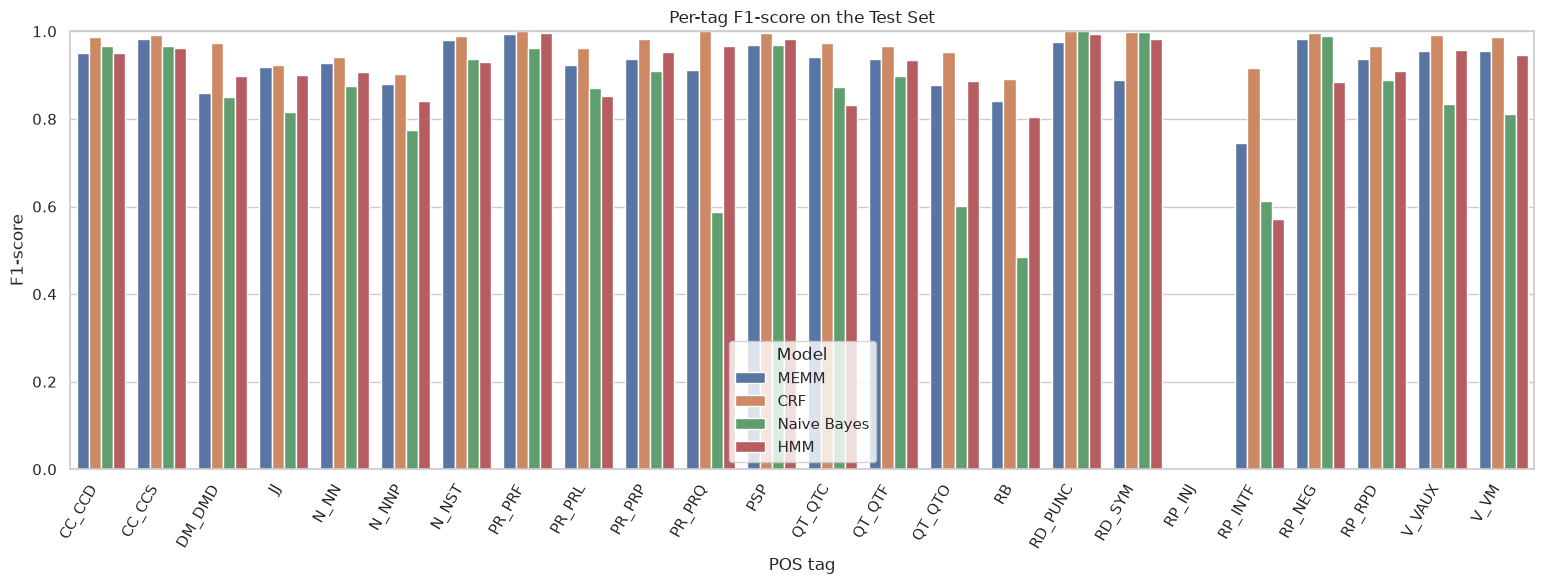

In [22]:
# Grouped bar chart. If there are many POS tags, rotate labels for readability.
plot_df = per_tag_df.melt(id_vars="tag", var_name="Model", value_name="F1-score")
plt.figure(figsize=(max(12, len(all_tags) * 0.65), 6))
sns.barplot(data=plot_df, x="tag", y="F1-score", hue="Model")
plt.title("Per-tag F1-score on the Test Set")
plt.xlabel("POS tag")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=60, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

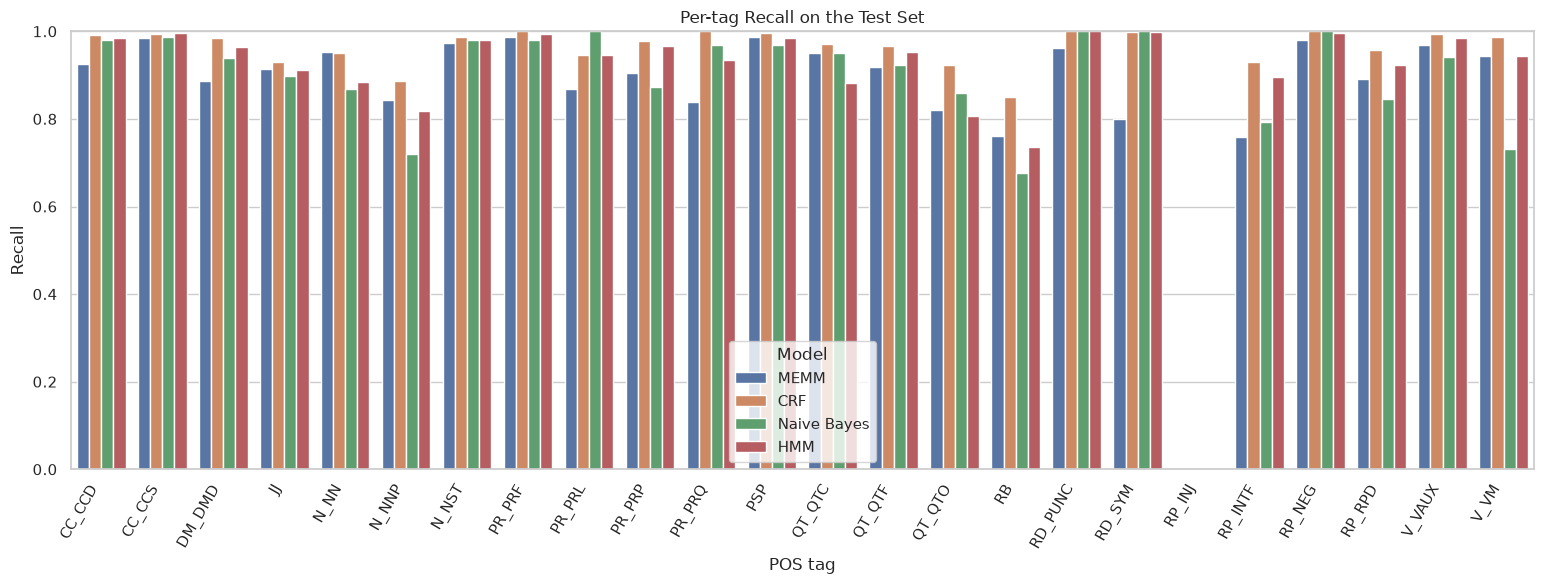

In [23]:
# Optional second chart: per-tag recall can reveal tags a model misses.
recall_rows = []
for tag in all_tags:
    row = {"tag": tag}
    for model_name, result in test_results.items():
        row[model_name] = result["report"].get(tag, {}).get("recall", 0.0)
    recall_rows.append(row)

recall_df = pd.DataFrame(recall_rows)
recall_plot = recall_df.melt(id_vars="tag", var_name="Model", value_name="Recall")
plt.figure(figsize=(max(12, len(all_tags) * 0.65), 6))
sns.barplot(data=recall_plot, x="tag", y="Recall", hue="Model")
plt.title("Per-tag Recall on the Test Set")
plt.xlabel("POS tag")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.xticks(rotation=60, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## 12. Save result tables

This saves aggregate scores and per-tag F1 scores beside the notebook so they can be included in the assignment report.

In [24]:
OUTPUT_DIR = Path("assignment9_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

overall_df.to_csv(OUTPUT_DIR / "overall_model_comparison.csv", index=False)
per_tag_df.to_csv(OUTPUT_DIR / "per_tag_f1_comparison.csv", index=False)
recall_df.to_csv(OUTPUT_DIR / "per_tag_recall_comparison.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-9/Lab-Assignment-9/assignment9_outputs


## 13. Discussion template

Fill in the discussion after running the notebook; do not report fabricated scores.

- **Best overall model:** Compare test macro F1 and weighted F1. Explain any difference between them.
- **Rare tags:** Identify tags with low support and compare their F1/recall. Rare classes are often harder to learn.
- **MEMM vs CRF:** MEMM uses locally normalized tag decisions and greedy previous-tag predictions here; CRF jointly scores the tag sequence and can use transition features.
- **Naive Bayes:** Useful lexical baseline, but it does not explicitly model tag transitions.
- **HMM:** Models tag transitions and word emissions; unseen words and sparse emissions may limit performance.
- **Limitations:** Document dataset format, split source, any fallback split, training time, and whether the split exactly matches Assignment 7.

## Important checks before submission

1. Confirm the loaded dataset is the **same dataset used in Assignment 7**.
2. Confirm that the original train/dev/test split is used if it exists.
3. Verify that sentence boundaries are preserved. A CSV without sentence IDs is treated as one-token sentences, which is not ideal for MEMM/CRF/HMM.
4. The notebook uses a practical NLTK maximum-entropy MEMM implementation; if your instructor specifically requires the repository's code, review its API and adapt the MEMM section accordingly.
5. Run all cells from top to bottom and include the generated score tables and plots in your report.